# Budget Meal Planner: Solving Student Nutrition with Linear Systems
**MATH 2138 â€“ Linear Algebra Applications in Data Science**

A student wants a meal that hits exact targets for **calories, protein and carbohydrates**
using three affordable foods. Each food is a vector of nutrients, so the question
*"how many servings of each food?"* becomes the linear system $A\mathbf{x} = \mathbf{b}$.

**How to run:** in Google Colab choose *Runtime â†’ Run all*. To try your own foods or
targets, edit the cell in Section 10 and run it again.

| Section | Linear algebra used | Lesson |
|---|---|---|
| 3 | Matrices, vectors, linear combinations | 1 |
| 4 | Determinant by cofactor expansion | 3 |
| 5 | Gauss-Jordan elimination, RREF | 2 |
| 6 | Cramer's rule | 3 |
| 7 | Inverse of a matrix, matrix multiplication | 1, 2 |
| 9 | Linear dependence, span, rank | 4 |

### Linear algebra in plain words

| Term | In this project it meansâ€¦ |
|---|---|
| **Vector** | A food's nutrition label as a list of numbers, e.g. rice = (205 kcal, 4.3 g protein, 44.5 g carbs) |
| **Matrix $A$** | The three labels placed side by side, one column per food |
| **Linear combination** | Eating some servings of each food and adding up the nutrients |
| **$A\mathbf{x}=\mathbf{b}$** | "Which servings $\mathbf{x}$ add up to my target $\mathbf{b}$?" |
| **Determinant** | One number saying whether the foods are truly different; 0 means one food is just a mix of the others |
| **Gauss-Jordan / RREF** | Simplifying the equations step by step until each one reads "$x_i$ = number" |
| **Cramer's rule** | A second, formula-based way to get the same answer, used as a check |
| **Inverse $A^{-1}$** | A reusable "undo" for $A$: any target times $A^{-1}$ gives the servings |
| **Rank** | How many of the foods are truly different |
| **Span** | Every nutrient total the foods can make |
| **Null space** | Swaps between foods that change nothing (e.g. 1 combo meal â†” 1 rice + 1 chicken) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
TOL = 1e-9          # numbers smaller than this are treated as zero

## 1. The data: nutrients per serving

Values are approximate, per one serving, based on USDA FoodData Central.
Costs are rough Philippine peso (â‚±) estimates for food prepared at home; replace them
with your own prices.

In [2]:
#                       kcal  protein(g) carbs(g)  cost(â‚±)
FOODS = {
    "Rice (1 cup cooked)":       (205, 4.3, 44.5,  5),
    "Egg (1 large)":             ( 78, 6.3,  0.6,  9),
    "Banana (1 medium)":         (105, 1.3, 27.0,  8),
    "Peanut butter (2 tbsp)":    (191, 7.1,  7.7, 14),
    "Chicken breast (100 g)":    (165, 31.0, 0.0, 35),
    "White bread (1 slice)":     ( 67, 1.9, 12.7,  4),
    "Milk (1 cup)":              (149, 7.7, 11.7, 20),
}
NUTRIENTS = ["Calories (kcal)", "Protein (g)", "Carbs (g)"]

food_table = pd.DataFrame(FOODS, index=NUTRIENTS + ["Cost (â‚±)"]).T
food_table

,Calories (kcal),Protein (g),Carbs (g),Cost (â‚±)
Rice (1 cup cooked),205.0,4.3,44.5,5.0
Egg (1 large),78.0,6.3,0.6,9.0
Banana (1 medium),105.0,1.3,27.0,8.0
Peanut butter (2 tbsp),191.0,7.1,7.7,14.0
Chicken breast (100 g),165.0,31.0,0.0,35.0
White bread (1 slice),67.0,1.9,12.7,4.0
Milk (1 cup),149.0,7.7,11.7,20.0


## 2. Student profiles (the targets)

Each student has a nutrient target **b** for one meal and a budget.

In [3]:
STUDENTS = {
    #                       kcal protein carbs  budget(â‚±)
    "A â€“ regular student":   (600, 25,  80,  80),
    "B â€“ varsity athlete":   (900, 45, 110, 100),
    "C â€“ high-protein diet": (500, 40,  30,  70),
    "D â€“ carb-loading":      (700, 10, 140,  60),
}
pd.DataFrame(STUDENTS, index=NUTRIENTS + ["Budget (â‚±)"]).T

,Calories (kcal),Protein (g),Carbs (g),Budget (â‚±)
A â€“ regular student,600,25,80,80
B â€“ varsity athlete,900,45,110,100
C â€“ high-protein diet,500,40,30,70
D â€“ carb-loading,700,10,140,60


## 3. Mathematical formulation: $A\mathbf{x} = \mathbf{b}$

Pick three foods. Each food $j$ is a nutrient vector $\mathbf{a}_j \in \mathbb{R}^3$, and these
vectors are the **columns** of $A$. If $x_j$ is the number of servings of food $j$, the meal's
nutrients are the linear combination

$$x_1\mathbf{a}_1 + x_2\mathbf{a}_2 + x_3\mathbf{a}_3 = A\mathbf{x} = \mathbf{b}.$$

Row $i$ of the system says: *(nutrient $i$ in food 1)Â·$x_1$ + (nutrient $i$ in food 2)Â·$x_2$ +
(nutrient $i$ in food 3)Â·$x_3$ = target for nutrient $i$*. The cost is the dot product
$\mathbf{c}\cdot\mathbf{x}$ with the price vector $\mathbf{c}$.

> **In plain words:** each food's nutrition label is a list of 3 numbers. Eating $x_1$ servings
> of food 1, $x_2$ of food 2 and $x_3$ of food 3 adds the labels up. We want that total to equal
> the target, which gives three equations (one per nutrient) in three unknowns.

In [4]:
def build_system(food_names):
    # Columns of A are the food vectors a_j; c holds the price of each food.
    A = np.array([FOODS[f][:3] for f in food_names], dtype=float).T   # transpose: foods -> columns
    c = np.array([FOODS[f][3] for f in food_names], dtype=float)
    return A, c

MY_FOODS = ["Rice (1 cup cooked)", "Peanut butter (2 tbsp)", "Chicken breast (100 g)"]
A, c = build_system(MY_FOODS)
b = np.array(STUDENTS["A â€“ regular student"][:3], dtype=float)

print("A (rows = nutrients, columns = foods):\n", A)
print("\nb (Student A's target):", b)
print("c (price per serving):  ", c)

A (rows = nutrients, columns = foods):
 [[205.  191.  165. ]
 [  4.3   7.1  31. ]
 [ 44.5   7.7   0. ]]

b (Student A's target): [600.  25.  80.]
c (price per serving):   [ 5. 14. 35.]


## 4. Does a unique meal plan exist? The determinant

By the Fundamental Theorem (Lesson 3), $A\mathbf{x}=\mathbf{b}$ has a **unique** solution for
every $\mathbf{b}$ if and only if $\det(A) \neq 0$. We compute the determinant ourselves by
**cofactor expansion** along the first row:

$$\det(A) = \sum_{j=1}^{n} (-1)^{1+j}\, a_{1j}\, \det(M_{1j}),$$

where $M_{1j}$ is $A$ with row 1 and column $j$ removed.

> **In plain words:** the determinant is one number that tells us whether the three foods are
> really different from each other. If it is 0, one food is just a mix of the other two and
> there is no single answer.

In [5]:
def det_cofactor(M):
    # Determinant by cofactor expansion along row 1 (recursive).
    n = M.shape[0]
    if n == 1:
        return M[0, 0]
    if n == 2:
        return M[0, 0] * M[1, 1] - M[0, 1] * M[1, 0]       # ad - bc
    total = 0.0
    for j in range(n):
        minor = np.delete(np.delete(M, 0, axis=0), j, axis=1)   # remove row 1, column j
        total += (-1) ** j * M[0, j] * det_cofactor(minor)      # sign (-1)^(1+j) with 0-based j
    return total

d = det_cofactor(A)
print(f"det(A) by cofactor expansion = {d:,.2f}")
print(f"det(A) by numpy (check)      = {np.linalg.det(A):,.2f}")
print("det(A) != 0  ->  the foods are linearly independent, so a unique plan exists."
      if abs(d) > TOL else "det(A) = 0  ->  no unique plan.")

det(A) by cofactor expansion = 167,882.40
det(A) by numpy (check)      = 167,882.40
det(A) != 0  ->  the foods are linearly independent, so a unique plan exists.


## 5. Solving with Gauss-Jordan elimination

We row-reduce the augmented matrix $[A \mid \mathbf{b}]$ to **reduced row echelon form** using the
three elementary row operations (Lesson 2):

* **Type I** â€“ swap two rows (we swap in the largest pivot to limit rounding error),
* **Type II** â€“ multiply a row by a nonzero number (to make the leading 1),
* **Type III** â€“ add a multiple of one row to another (to clear the column).

The last column of the RREF is the solution $\mathbf{x}$.

> **In plain words:** we simplify the three equations using only three allowed moves: swap two
> equations, multiply one by a number, or subtract a multiple of one from another. At the end
> each row reads "$x_i$ = number", so the answer can be read off directly.

In [6]:
def gauss_jordan(M, n_coef_cols=None, verbose=False):
    # Reduce M to RREF. Only the first n_coef_cols columns are used as pivot columns
    # (so the right-hand side of [A | b] or [A | I] is never chosen as a pivot).
    M = M.astype(float).copy()
    rows, cols = M.shape
    n_coef_cols = cols if n_coef_cols is None else n_coef_cols
    pivots, steps, r = [], [], 0
    for col in range(n_coef_cols):
        if r == rows:
            break
        p = r + np.argmax(np.abs(M[r:, col]))          # best pivot row for this column
        if abs(M[p, col]) < TOL:
            continue                                   # no pivot: free variable
        if p != r:
            M[[r, p]] = M[[p, r]]
            steps.append(f"Type I:   R{r+1} <-> R{p+1}")
        piv = M[r, col]
        M[r] = M[r] / piv
        steps.append(f"Type II:  R{r+1} <- (1/{piv:.4g}) R{r+1}")
        for i in range(rows):
            if i != r and abs(M[i, col]) > TOL:
                f = M[i, col]
                M[i] = M[i] - f * M[r]
                steps.append(f"Type III: R{i+1} <- R{i+1} - ({f:.4g}) R{r+1}")
        pivots.append(col)
        r += 1
    M[np.abs(M) < TOL] = 0.0
    if verbose:
        print("\n".join(steps))
    return M, pivots

augmented = np.column_stack([A, b])
print("[A | b] =\n", augmented, "\n")
R, pivots = gauss_jordan(augmented, n_coef_cols=3, verbose=True)
print("\nRREF =\n", R)
x = R[:, -1]
print("\nServings x =", x)

[A | b] =
 [[205.  191.  165.  600. ]
 [  4.3   7.1  31.   25. ]
 [ 44.5   7.7   0.   80. ]] 

Type II:  R1 <- (1/205) R1
Type III: R2 <- R2 - (4.3) R1
Type III: R3 <- R3 - (44.5) R1
Type I:   R2 <-> R3
Type II:  R2 <- (1/-33.76) R2
Type III: R1 <- R1 - (0.9317) R2
Type III: R3 <- R3 - (3.094) R2
Type II:  R3 <- (1/24.26) R3
Type III: R1 <- R1 - (-0.1836) R3
Type III: R2 <- R2 - (1.061) R3

RREF =
 [[1.    0.    0.    1.599]
 [0.    1.    0.    1.147]
 [0.    0.    1.    0.322]]

Servings x = [1.599 1.147 0.322]


In [7]:
def describe_plan(food_names, x, c, budget=None):
    plan = pd.DataFrame({"Servings": x.round(2), "Cost (â‚±)": (c * x).round(2)}, index=food_names)
    print(plan.to_string())
    cost = c @ x                                       # dot product c . x
    print(f"\nTotal cost cÂ·x = â‚±{cost:.2f}")
    if np.any(x < -TOL):
        print("NOT FEASIBLE: a negative serving count cannot be eaten.")
    elif budget is not None and cost > budget + TOL:
        print(f"Over budget (â‚±{budget}).")
    else:
        print("Feasible" + (f" and within budget (â‚±{budget})." if budget else "."))

describe_plan(MY_FOODS, x, c, budget=STUDENTS["A â€“ regular student"][3])

                        Servings  Cost (â‚±)
Rice (1 cup cooked)         1.60        8.00
Peanut butter (2 tbsp)      1.15       16.05
Chicken breast (100 g)      0.32       11.27

Total cost cÂ·x = â‚±35.32
Feasible and within budget (â‚±80).


## 6. Checking the answer with Cramer's rule

Because $\det(A)\neq 0$, Cramer's rule gives each unknown directly:
$x_i = \dfrac{\det(A_i)}{\det(A)}$, where $A_i$ is $A$ with column $i$ replaced by $\mathbf{b}$.
Getting the same answer by a completely different method is our first test.

> **In plain words:** a second, formula-based way to compute each serving. If two unrelated
> methods agree, the answer is very likely right.

In [8]:
def cramer(A, b):
    dA = det_cofactor(A)
    x = np.zeros(len(b))
    for i in range(len(b)):
        Ai = A.copy()
        Ai[:, i] = b                    # replace column i with b
        x[i] = det_cofactor(Ai) / dA
    return x

x_cramer = cramer(A, b)
print("Gauss-Jordan:", x)
print("Cramer's rule:", x_cramer)
print("Same answer:", np.allclose(x, x_cramer))

Gauss-Jordan: [1.599 1.147 0.322]
Cramer's rule: [1.599 1.147 0.322]
Same answer: True


## 7. Planning for every student at once with $A^{-1}$

All students use the same foods, so they share the same $A$. We find $A^{-1}$ once by
row-reducing $[A \mid I] \to [I \mid A^{-1}]$, then put every target vector as a column of
$B$ and compute all plans in one matrix multiplication:

$$X = A^{-1}B.$$

> **In plain words:** $A^{-1}$ is a reusable "undo" for $A$. We compute it once, and every
> student's servings then come from one multiplication. Student D wants lots of carbs but little
> protein; rice brings too much protein along, so the only exact answer needs *negative* chicken,
> which is impossible.

In [9]:
def inverse_gauss_jordan(A):
    n = A.shape[0]
    R, pivots = gauss_jordan(np.hstack([A, np.eye(n)]), n_coef_cols=n)
    if len(pivots) < n:
        raise ValueError("A is singular: it has no inverse.")
    return R[:, n:]                      # right half is A^-1

A_inv = inverse_gauss_jordan(A)
print("A^-1 =\n", A_inv)
print("\nA @ A^-1 = I ?", np.allclose(A @ A_inv, np.eye(3)))

names = list(STUDENTS)
B = np.array([STUDENTS[s][:3] for s in names], dtype=float).T    # one column per student
X = A_inv @ B                                                    # one column of servings per student

results = pd.DataFrame(X.T.round(2), index=names, columns=MY_FOODS)
results["Cost (â‚±)"] = (c @ X).round(2)
results["Budget (â‚±)"] = [STUDENTS[s][3] for s in names]
results["Verdict"] = ["Not feasible (negative servings)" if np.any(X[:, k] < -TOL)
                      else ("Over budget" if c @ X[:, k] > STUDENTS[s][3] else "OK")
                      for k, s in enumerate(names)]
results

A^-1 =
 [[-0.001  0.008  0.028]
 [ 0.008 -0.044 -0.034]
 [-0.002  0.041  0.004]]

A @ A^-1 = I ? True


,Rice (1 cup cooked),Peanut butter (2 tbsp),Chicken breast (100 g),Cost (â‚±),Budget (â‚±),Verdict
A â€“ regular student,1.60,1.15,0.32,35.32,80,OK
B â€“ varsity athlete,2.17,1.73,0.75,61.46,100,OK
C â€“ high-protein diet,0.44,1.35,0.92,53.31,70,OK
D â€“ carb-loading,3.04,0.61,-0.24,15.36,60,Not feasible (negative servings)


## 8. Seeing the linear combination

Each bar is a student's target. The coloured pieces are $x_j\mathbf{a}_j$: how much of that
nutrient comes from each food. They stack up exactly to the target, which is what
$x_1\mathbf{a}_1 + x_2\mathbf{a}_2 + x_3\mathbf{a}_3 = \mathbf{b}$ means. Student D's chart has a
piece below zero: the negative serving that makes that plan impossible.

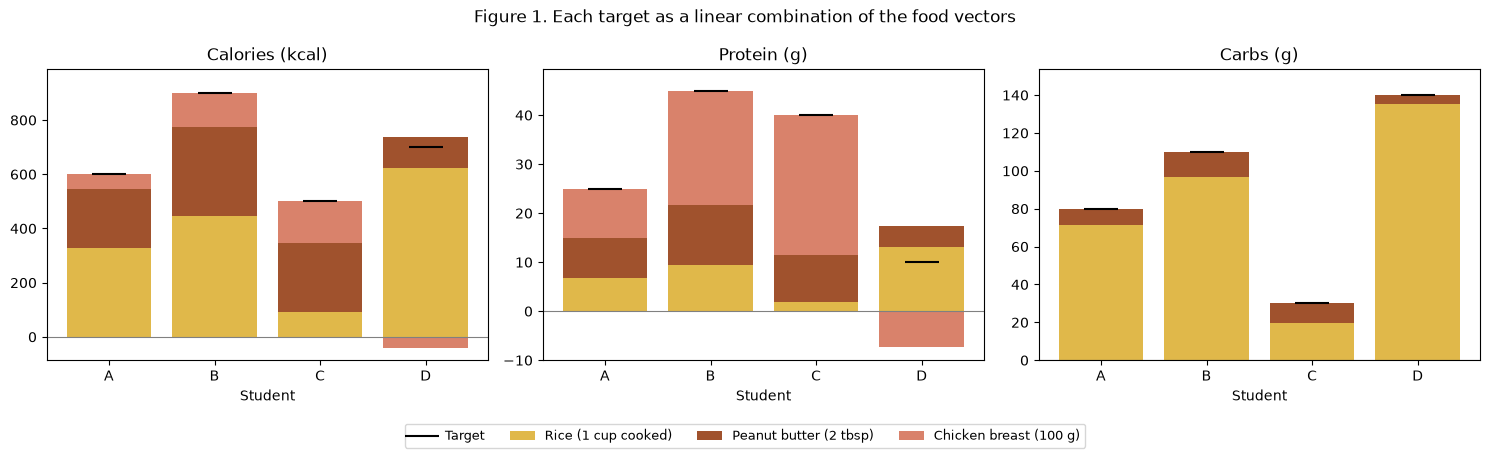

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
colors = ["#e0b84a", "#a0522d", "#d9826b"]
for i, (ax, nutrient) in enumerate(zip(axes, NUTRIENTS)):
    pos_bottom = np.zeros(len(names)); neg_bottom = np.zeros(len(names))
    for j, food in enumerate(MY_FOODS):
        part = X[j] * A[i, j]                         # x_j * (nutrient i in food j)
        bottom = np.where(part >= 0, pos_bottom, neg_bottom)
        ax.bar(range(len(names)), part, bottom=bottom, color=colors[j], label=food)
        pos_bottom += np.clip(part, 0, None); neg_bottom += np.clip(part, None, 0)
    ax.scatter(range(len(names)), B[i], color="black", marker="_", s=600, zorder=3, label="Target")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xticks(range(len(names)), [n.split(" â€“ ")[0] for n in names])
    ax.set_title(nutrient); ax.set_xlabel("Student")
    ax.set_ylim(top=1.1 * max(pos_bottom.max(), B[i].max()))
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=9)
fig.suptitle("Figure 1. Each target as a linear combination of the food vectors")
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

## 9. When the foods are linearly dependent

A canteen sells a **"Chicken rice meal" = 1 cup rice + 100 g chicken**. Its nutrient vector is
exactly $\mathbf{a}_{\text{rice}} + \mathbf{a}_{\text{chicken}}$, so the set
{rice, chicken, combo} is **linearly dependent**. Then:

* $\det(A) = 0$ and $\operatorname{rank}(A) = 2 < 3$,
* the three foods only **span a plane** (a 2-dimensional subspace) in $\mathbb{R}^3$,
* a target **on** the plane has infinitely many plans; a target **off** the plane has none.

> **In plain words:** the combo meal adds nothing new, because it is just rice and chicken
> together. With only two truly different foods, everything you can make lies on one flat sheet.
> A target off the sheet is unreachable (the RREF ends in the contradiction $0 = $ a nonzero
> number); a target on the sheet can be reached in endless ways.

In [11]:
rice, chicken = np.array(FOODS["Rice (1 cup cooked)"]), np.array(FOODS["Chicken breast (100 g)"])
combo_nutrients = rice[:3] + chicken[:3]                    # a linear combination of two foods
FOODS["Chicken rice meal"] = (*combo_nutrients, 35)          # combo costs â‚±35 vs â‚±40 bought separately
DEP_FOODS = ["Rice (1 cup cooked)", "Chicken breast (100 g)", "Chicken rice meal"]
A_dep, c_dep = build_system(DEP_FOODS)

print("A_dep =\n", A_dep)
print(f"\ndet(A_dep) = {det_cofactor(A_dep):.6f}")

def solve_and_classify(A, b):
    R, pivots = gauss_jordan(np.column_stack([A, b]), n_coef_cols=A.shape[1])
    rank = len(pivots)
    if any(np.all(np.abs(row[:-1]) < TOL) and abs(row[-1]) > TOL for row in R):
        kind = "NO solution (b is not in the span of the foods)"
    elif rank == A.shape[1]:
        kind = "UNIQUE solution"
    else:
        kind = f"INFINITELY many solutions ({A.shape[1] - rank} free variable)"
    return R, rank, kind

for label, target in [("Student A's target", b),
                      ("2 rice + 1 chicken", 2 * rice[:3] + chicken[:3])]:
    R, rank, kind = solve_and_classify(A_dep, target)
    print(f"\n--- {label}: b = {target} ---")
    print("RREF of [A | b] =\n", R)
    print(f"rank(A) = {rank}  ->  {kind}")

A_dep =
 [[205.  165.  370. ]
 [  4.3  31.   35.3]
 [ 44.5   0.   44.5]]

det(A_dep) = 0.000000

--- Student A's target: b = [600.  25.  80.] ---
RREF of [A | b] =
 [[  1.      0.      1.      1.798]
 [  0.      1.      1.      1.403]
 [  0.      0.      0.    -26.217]]
rank(A) = 2  ->  NO solution (b is not in the span of the foods)

--- 2 rice + 1 chicken: b = [575.   39.6  89. ] ---
RREF of [A | b] =
 [[1. 0. 1. 2.]
 [0. 1. 1. 1.]
 [0. 0. 0. 0.]]
rank(A) = 2  ->  INFINITELY many solutions (1 free variable)


For the second target, let the combo meal be the free variable $x_3 = t$. The RREF reads
$x_1 + x_3 = 2$ and $x_2 + x_3 = 1$, so every plan has the form

$$\mathbf{x} = \begin{bmatrix}2\\1\\0\end{bmatrix} + t\begin{bmatrix}-1\\-1\\1\end{bmatrix},\quad 0 \le t \le 1.$$

The vector $(-1,-1,1)$ spans the **null space** of $A$: swapping one rice and one chicken for
one combo meal leaves the nutrients unchanged. Only the price changes: the combo costs â‚±35
instead of â‚±5 + â‚±35 = â‚±40, so the cheapest plan is $t = 1$.

In [12]:
for t in [0, 0.5, 1]:
    xt = np.array([2, 1, 0]) + t * np.array([-1, -1, 1])
    print(f"t = {t}: servings = {xt},  nutrients A x = {A_dep @ xt},  cost = â‚±{c_dep @ xt:.2f}")

t = 0: servings = [2 1 0],  nutrients A x = [575.   39.6  89. ],  cost = â‚±45.00
t = 0.5: servings = [1.5 0.5 0.5],  nutrients A x = [575.   39.6  89. ],  cost = â‚±42.50
t = 1: servings = [1 0 1],  nutrients A x = [575.   39.6  89. ],  cost = â‚±40.00


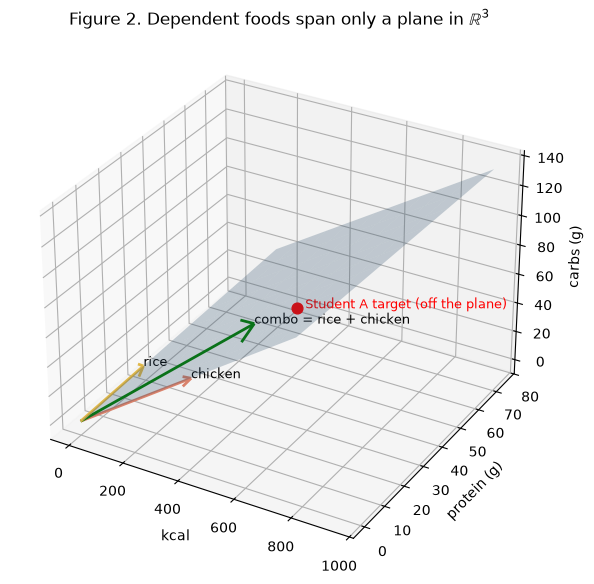

In [13]:
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(projection="3d")
s, t = np.meshgrid(np.linspace(0, 3, 10), np.linspace(0, 2, 10))
plane = s[..., None] * rice[:3] + t[..., None] * chicken[:3]          # span{rice, chicken}
ax.plot_surface(plane[..., 0], plane[..., 1], plane[..., 2], alpha=0.25, color="steelblue")
for vec, name, col in [(rice[:3], "rice", "#e0b84a"), (chicken[:3], "chicken", "#d9826b"),
                       (A_dep[:, 2], "combo = rice + chicken", "green")]:
    ax.quiver(0, 0, 0, *vec, color=col, lw=2, arrow_length_ratio=0.08)
    ax.text(*vec, name, fontsize=9)
ax.scatter(*b, color="red", s=60)
ax.text(*b, "  Student A target (off the plane)", color="red", fontsize=9)
ax.set_xlabel("kcal"); ax.set_ylabel("protein (g)"); ax.set_zlabel("carbs (g)")
ax.set_title(r"Figure 2. Dependent foods span only a plane in $\mathbb{R}^3$")
plt.tight_layout(); plt.show()

## 10. Try it yourself

Change the three foods (copy any names from Section 1), the target and the budget, then run
the cell. The program explains the result in plain words.

**Warning check:** protein and carbs each give about 4 kcal per gram, so a target needs at least
$4(P + C)$ kcal. If you ask for less, no real foods can ever meet it, and the program warns you.
(We allow 10% leeway because food labels round, and fibre counts as carbs but gives fewer kcal.)

In [14]:
def target_warning(target):
    kcal, protein, carbs = target
    if min(target) < 0:
        return "Targets cannot be negative."
    minimum = 4 * (protein + carbs)            # kcal from protein and carbs alone
    if minimum > 1.10 * kcal:
        return (f"Impossible target: {protein:g} g protein + {carbs:g} g carbs already give "
                f"4 x ({protein:g} + {carbs:g}) = {minimum:.0f} kcal, more than your {kcal:g} kcal. "
                f"No real foods can do this. Raise calories or lower protein/carbs.")
    return None

def plan_meal(food_names, target, budget=None):
    A, c = build_system(food_names)
    warning = target_warning(target)
    if warning:
        print("WARNING:", warning, "\n")
    d = det_cofactor(A)
    R, rank, kind = solve_and_classify(A, np.array(target, dtype=float))
    print(f"det(A) = {d:,.2f}   rank(A) = {rank}   ->  {kind}\n")
    if kind != "UNIQUE solution":
        print("In plain words: one of your foods is just a mix of the others, so only "
              f"{rank} of them are truly different.")
        print("No plan exists. Swap one food." if kind.startswith("NO") else
              "Many plans exist; pick the cheapest, or swap a food for a single answer.")
        return
    print("In plain words: your foods are different enough, so exactly one combination works.\n")
    x = R[:, -1]
    describe_plan(food_names, x, c, budget)
    for name, xi in zip(food_names, x):
        if xi < -TOL:
            print(f"\nIn plain words: {xi:.2f} servings of {name} means taking it AWAY from the "
                  f"meal, which is impossible. Swap {name} for another food or change the target.")

plan_meal(["Egg (1 large)", "Banana (1 medium)", "Milk (1 cup)"],
          target=(600, 25, 80), budget=80)

det(A) = 2,944.41   rank(A) = 3   ->  UNIQUE solution

In plain words: your foods are different enough, so exactly one combination works.

                   Servings  Cost (â‚±)
Egg (1 large)          1.17       10.49
Banana (1 medium)      2.10       16.77
Milk (1 cup)           1.94       38.78

Total cost cÂ·x = â‚±66.05
Feasible and within budget (â‚±80).


In [15]:
# An impossible target: 4 x (100 + 100) = 800 kcal > 700 kcal, so the program warns first.
plan_meal(["Chicken rice meal", "Egg (1 large)", "Banana (1 medium)"],
          target=(700, 100, 100), budget=1000)


det(A) = -34,393.95   rank(A) = 3   ->  UNIQUE solution

In plain words: your foods are different enough, so exactly one combination works.

                   Servings  Cost (â‚±)
Chicken rice meal      4.12      144.28
Egg (1 large)         -6.62      -59.56
Banana (1 medium)     -2.94      -23.55

Total cost cÂ·x = â‚±61.17
NOT FEASIBLE: a negative serving count cannot be eaten.

In plain words: -6.62 servings of Egg (1 large) means taking it AWAY from the meal, which is impossible. Swap Egg (1 large) for another food or change the target.

In plain words: -2.94 servings of Banana (1 medium) means taking it AWAY from the meal, which is impossible. Swap Banana (1 medium) for another food or change the target.


## 11. Testing

Each check compares our hand-written linear algebra with an independent method.

In [16]:
checks = {
    "A x = b for Student A (substitution)":           np.allclose(A @ x, b),
    "Gauss-Jordan matches numpy.linalg.solve":         np.allclose(x, np.linalg.solve(A, b)),
    "Gauss-Jordan matches Cramer's rule":              np.allclose(x, cramer(A, b)),
    "Cofactor det matches numpy.linalg.det":           np.isclose(det_cofactor(A), np.linalg.det(A)),
    "A A^-1 = I":                                      np.allclose(A @ A_inv, np.eye(3)),
    "A X = B for all students":                        np.allclose(A @ X, B),
    "Dependent foods: det = 0":                        abs(det_cofactor(A_dep)) < 1e-6,
    "Dependent foods: rank = 2":                       solve_and_classify(A_dep, b)[1] == 2,
    "Impossible target (700, 100, 100) is flagged":    target_warning((700, 100, 100)) is not None,
    "No real food is flagged as impossible":           all(target_warning(v[:3]) is None
                                                           for v in FOODS.values()),
}
for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
assert all(checks.values())

PASS  A x = b for Student A (substitution)
PASS  Gauss-Jordan matches numpy.linalg.solve
PASS  Gauss-Jordan matches Cramer's rule
PASS  Cofactor det matches numpy.linalg.det
PASS  A A^-1 = I
PASS  A X = B for all students
PASS  Dependent foods: det = 0
PASS  Dependent foods: rank = 2
PASS  Impossible target (700, 100, 100) is flagged
PASS  No real food is flagged as impossible
